# Simple manual-range AC dip estimates — current workflow

For every track, take the **raw maximum for a peak or raw minimum for a trough inside the exact inclusive manual depth range**. Fit a straight line through all those depth picks. No smoothing of picks, flag exclusion, trimming, prominence test, matching tolerance, directional expansion, outlier removal, angle cap, R² cutoff, residual cutoff, or stability test is applied. Each window is independent; overlapping windows are not deduplicated.

If multiple raw samples share the extremum, use the shallowest tied sample. Missing/nonfinite measurements cannot supply an extremum and are reported explicitly. A line requires two distinct lateral coordinates; a conventional residual-based interval requires at least three picks. These are mathematical requirements, not quality filters. Every selected window in this dataset has a pick on every track.

The slope is depth in mm per lateral mm; angle = arctan(slope). Ordinary least-squares standard errors and Student-t critical values (n−2 degrees of freedom) give the 95% slope interval, transformed to angle. There is no extra uncertainty floor. `ci_width_deg` is the **full** angular interval width, upper minus lower. The interval describes regression uncertainty conditional on the picked depths; it does not establish correct feature identity.

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/metadata.csv").exists())
WORK = ROOT / "agentic_workspace/dip_angles"
sys.path.insert(0, str(WORK))
from simple_manual import run_simple
fits, picks = run_simple()
print(f"{len(fits)} fits, {len(picks)} raw track picks")

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


214abcdefg: 4 windows


216abcdef: 4 windows


217abc: 9 windows


219b: 8 windows


221abcd: 0 windows


... (8 outputs left out)

230a: 0 windows


230de: 0 windows


231: 0 windows


47 fits, 486 raw track picks


In [2]:
display(fits[["window_id", "core", "section", "kind", "n_tracks", "depth_m", "angle_deg",
              "ci_low_deg", "ci_high_deg", "ci_width_deg", "r2", "rmse_mm"]].round(4))

,window_id,core,section,kind,n_tracks,depth_m,angle_deg,ci_low_deg,ci_high_deg,ci_width_deg,r2,rmse_mm
0,1,DEN13A,214abcdefg,peak,10,197.6492,-13.8400,-17.4513,-10.1131,7.3381,0.8972,1.1978
1,2,DEN13A,214abcdefg,trough,10,196.9862,-16.0600,-18.1020,-13.9752,4.1268,0.9731,0.6872
2,3,DEN13A,214abcdefg,trough,10,197.0596,-20.2739,-25.5840,-14.5748,11.0091,0.8835,1.9268
3,4,DEN13A,214abcdefg,trough,10,197.2675,-9.5299,-12.1070,-6.9133,5.1938,0.8960,0.8214
4,5,DEN13A,216abcdef,trough,10,198.9270,-7.5605,-10.1089,-4.9817,5.1273,0.8494,0.8026
5,6,DEN13A,216abcdef,trough,10,199.2407,-21.6666,-25.4792,-17.6415,7.8376,0.9435,1.3961
6,7,DEN13A,216abcdef,trough,10,199.3025,-12.1754,-15.0710,-9.2152,5.8558,0.9153,0.9428
7,8,DEN13A,216abcdef,peak,10,199.2837,-11.8265,-14.5186,-9.0805,5.4381,0.9222,0.8732
8,9,DEN13A,217abc,trough,10,199.6518,12.9857,10.4480,15.4727,5.0246,0.9430,0.8139
9,10,DEN13A,217abc,trough,10,199.6786,15.2228,13.1445,17.2609,4.1164,0.9706,0.6799


## Overall basal-core dip profile

All estimates share one continuous depth axis, covering the full measured basal interval. Uniform black markers show estimates with horizontal 95% error bars; no section divisions or offsets are applied.

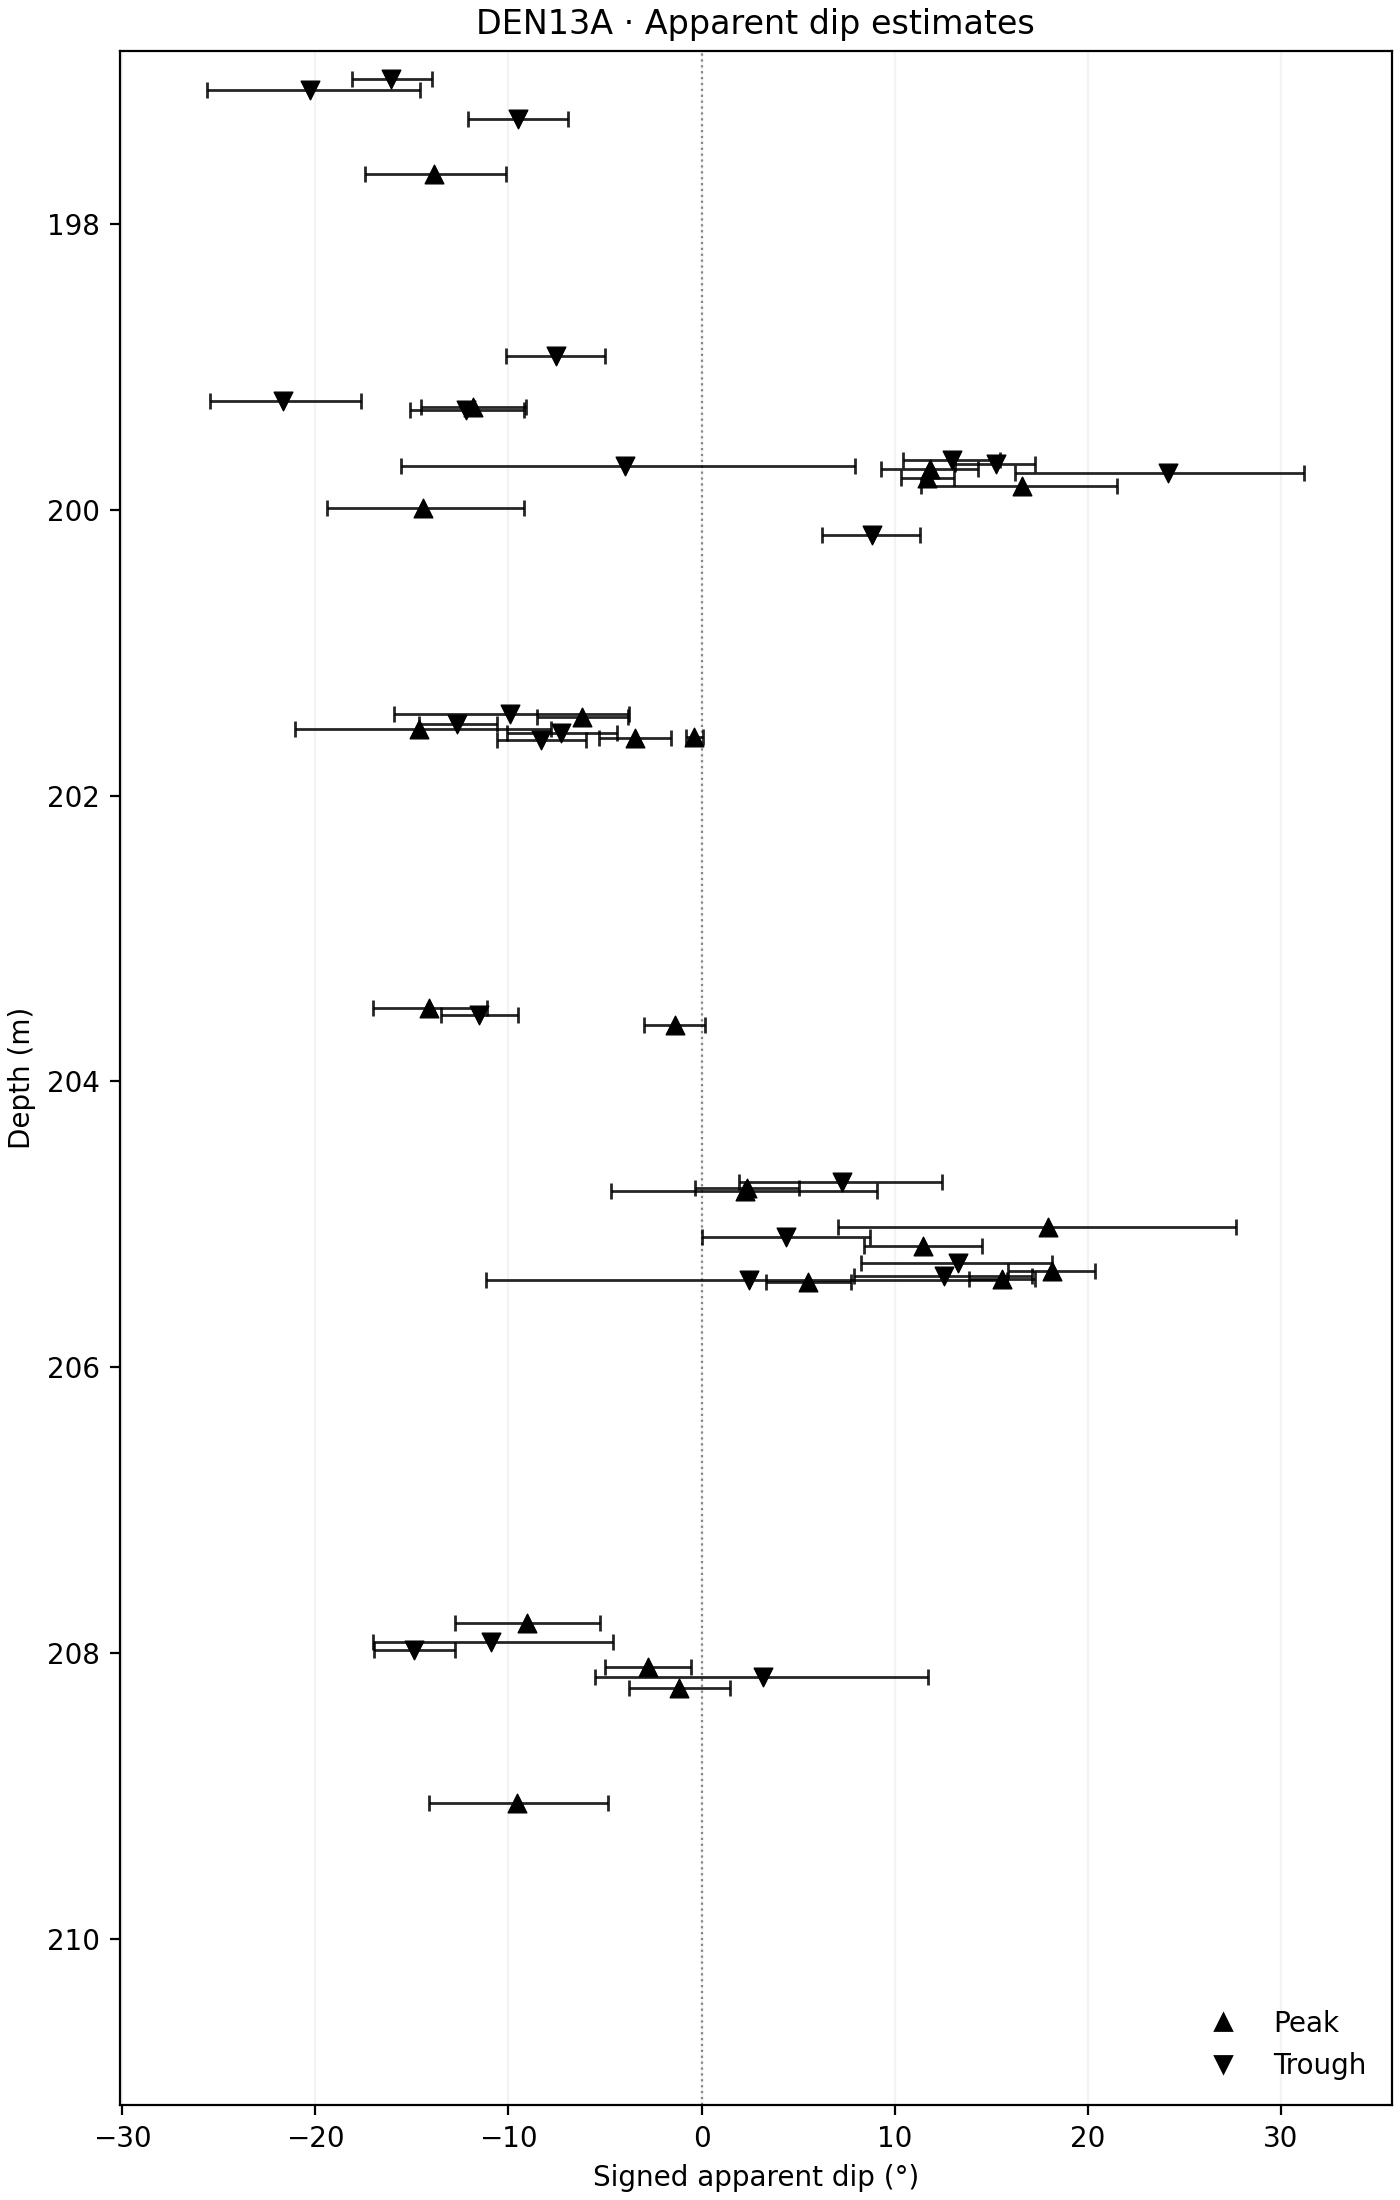

In [3]:
display(Image(filename=str(ROOT / "figures/dip_angles/simple_manual/DEN13A-overall-dips.png")))

## Section figures

Every section has a figure in `figures/dip_angles/simple_manual/`. On the left, the map uses median smoothing and outer-track normalization **for display only**, with raw flag overlays. Picks and regression always use unmodified values from the cleaned AC files. Flags do not exclude picks. On the half-width right panel, uniform black markers show the estimates and horizontal bars show their 95% angle intervals. Axis limits are determined by the plotted results, with no dip cap.

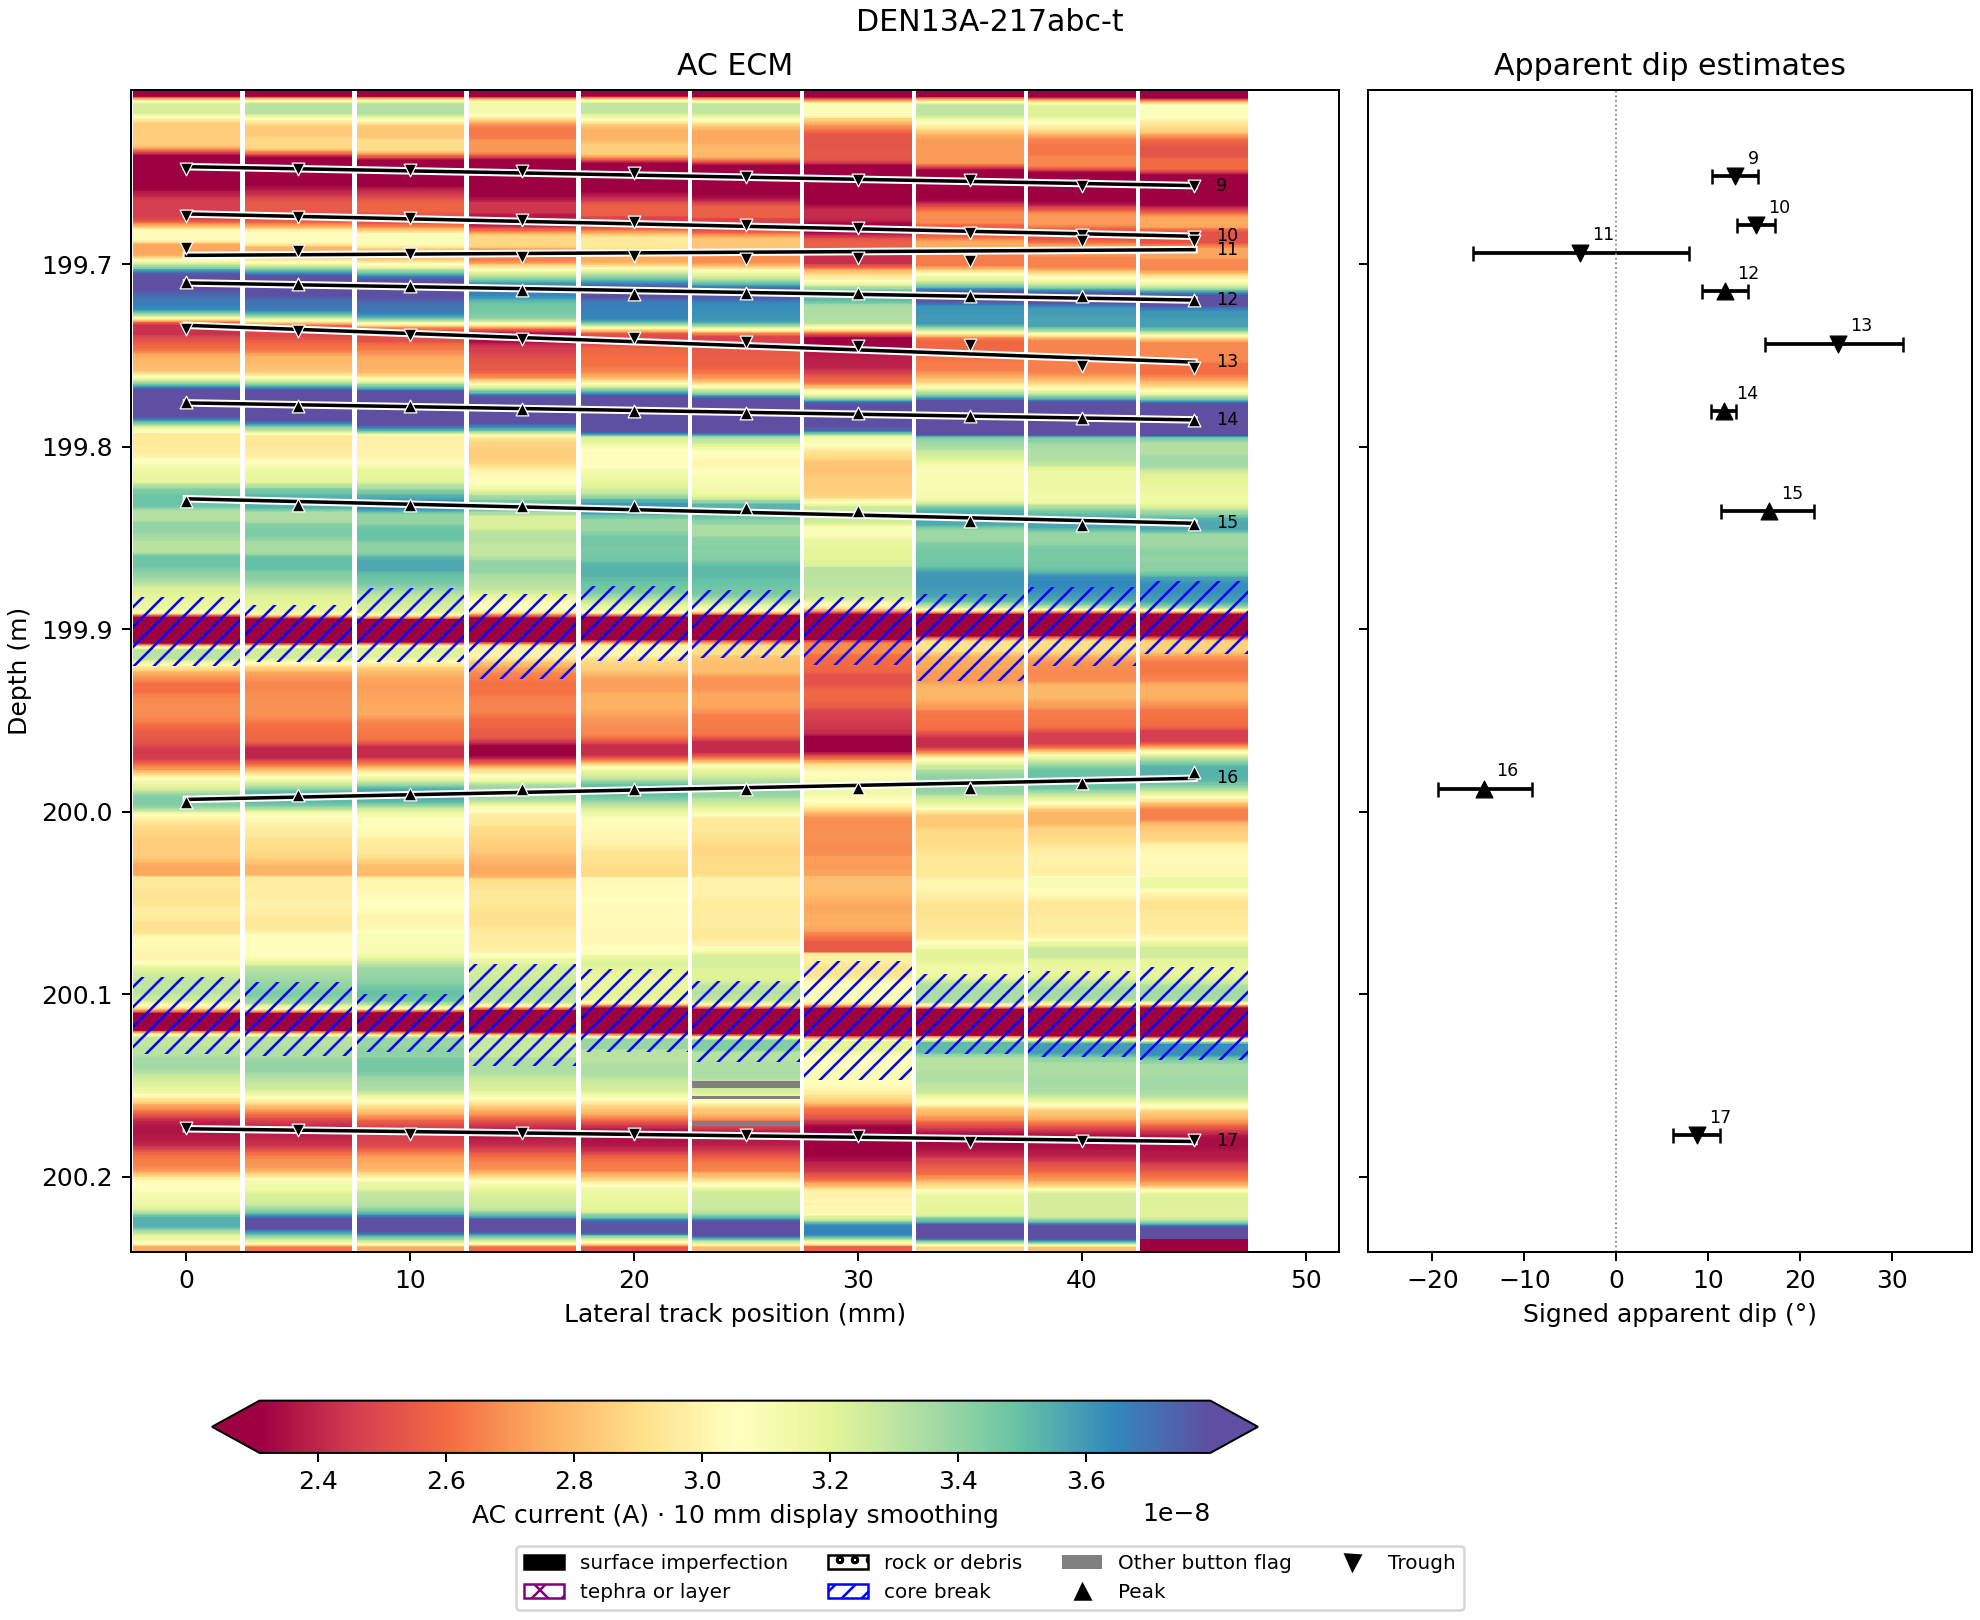

In [4]:
SECTION = "217abc"
display(Image(filename=str(ROOT / f"figures/dip_angles/simple_manual/DEN13A-{SECTION}-t-simple.png")))

## Files and validation

`simple_results/fits.csv` contains every window fit. `picks.csv` records the raw source row, current, depth, tie count, flag status, and residual for every track. `input_windows.csv` snapshots the unchanged manual ranges; `input_sha256.json` fingerprints inputs. Superseded threshold-based workflows have been removed.

`validate_simple.py` checks every actual pick against the raw within-window extremum, verifies all tracks were included, tests flagged/boundary picks and ties, and independently checks the regression and interval calculation.

In [5]:
from validate_simple import validate
display(validate())

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


{'windows': 47,
 'fits': 47,
 'picks': 486,
 'every_track_included': True,
 'raw_extrema_verified': True,
 'flagged_and_boundary_picks_retained': True,
 'slope_and_interval_verified': True}